saved the figure


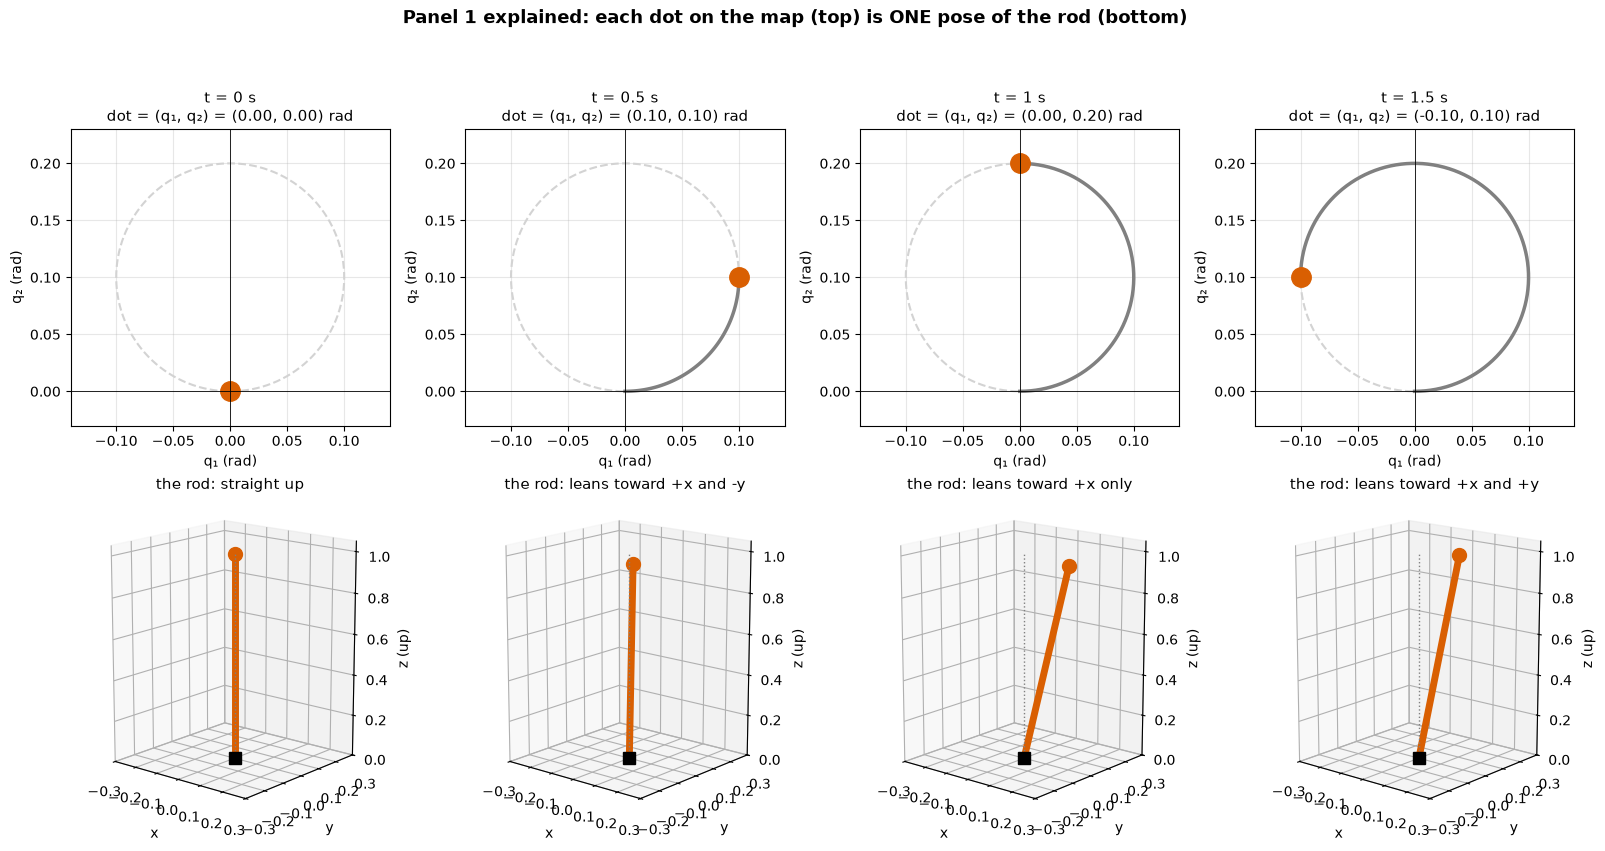

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ─────────────────────────────────────────────
# STEP 1: the path in joint angles (equation 8.1)
# What we have: A = 0.1 rad, omega_r = pi rad/s
# What we want: (q1, q2) at t = 0, 0.5, 1, 1.5 s and along the whole circle
# Why: each map point is a pair of hinge angles
# Formulas:
#   q1 = A sin(omega_r t),   q2 = A (1 - cos(omega_r t))
# ─────────────────────────────────────────────
A = 0.1  # rad
omega_r = np.pi  # rad/s
t_dense = np.linspace(0.0, 2.0, 400)  # s
q1_dense = A * np.sin(omega_r * t_dense)  # rad
q2_dense = A * (1.0 - np.cos(omega_r * t_dense))  # rad
t_marks = [0.0, 0.5, 1.0, 1.5]  # s
lean_words = ["straight up", "leans toward +x and -y", "leans toward +x only", "leans toward +x and +y"]

# ─────────────────────────────────────────────
# STEP 2: rod pose from the two angles
# What we have: q1 (rotation about x), q2 (rotation about y)
# What we want: tip position of a rod of length L = 1 m
# Why: to draw the real rod under each map point
# Formulas:
#   tip = L (sin q2, -sin q1 cos q2, cos q1 cos q2)
# ─────────────────────────────────────────────
L = 1.0  # m


def tip_position(q1, q2):
    return L * np.array([np.sin(q2), -np.sin(q1) * np.cos(q2), np.cos(q1) * np.cos(q2)])  # m


# ─────────────────────────────────────────────
# STEP 3: figure, top row = the map, bottom row = the rod
# What we have: four times
# What we want: for each time, the dot on the map and the rod below it
# Why: shows that one map point is one rod pose
# ─────────────────────────────────────────────
figure = plt.figure(figsize=(16, 8.6))
for column, t in enumerate(t_marks):
    q1 = A * np.sin(omega_r * t)
    q2 = A * (1.0 - np.cos(omega_r * t))
    passed = t_dense <= t

    ax_top = figure.add_subplot(2, 4, column + 1)
    ax_top.plot(q1_dense, q2_dense, "--", color="lightgray", linewidth=1.5)
    ax_top.plot(q1_dense[passed], q2_dense[passed], "-", color="gray", linewidth=2.5)
    ax_top.plot(q1, q2, "o", color="#d95f02", markersize=14)
    ax_top.axhline(0, color="black", linewidth=0.6)
    ax_top.axvline(0, color="black", linewidth=0.6)
    ax_top.set_xlim(-0.14, 0.14)
    ax_top.set_ylim(-0.03, 0.23)
    ax_top.set_aspect("equal")
    ax_top.set_xlabel("q₁ (rad)")
    ax_top.set_ylabel("q₂ (rad)")
    ax_top.grid(alpha=0.3)
    ax_top.set_title(f"t = {t:g} s\ndot = (q₁, q₂) = ({q1:.2f}, {q2:.2f}) rad", fontsize=11)

    ax_rod = figure.add_subplot(2, 4, column + 5, projection="3d")
    tip = tip_position(q1, q2)
    ax_rod.plot([0, tip[0]], [0, tip[1]], [0, tip[2]], color="#d95f02", linewidth=5)
    ax_rod.plot([tip[0]], [tip[1]], [tip[2]], "o", color="#d95f02", markersize=10)
    ax_rod.plot([0, 0], [0, 0], [0, 1.0], ":", color="gray", linewidth=1)  # upright reference
    ax_rod.plot([0], [0], [0], "ks", markersize=8)
    ax_rod.set_xlim(-0.3, 0.3)
    ax_rod.set_ylim(-0.3, 0.3)
    ax_rod.set_zlim(0.0, 1.05)
    ax_rod.set_box_aspect((1, 1, 1.3))
    ax_rod.view_init(elev=15, azim=-50)
    ax_rod.set_xlabel("x")
    ax_rod.set_ylabel("y")
    ax_rod.set_zlabel("z (up)")
    ax_rod.set_title(f"the rod: {lean_words[column]}", fontsize=11)

figure.suptitle("Panel 1 explained: each dot on the map (top) is ONE pose of the rod (bottom)", fontsize=13, fontweight="bold")
figure.tight_layout(rect=[0, 0, 1, 0.94])
figure.savefig(os.path.join(RESULT_DIR, f"map_to_rod_{TIMESTAMP}.png"), dpi=150)
print("saved the figure")
plt.show()